In [91]:
import torch  
import torch.nn as nn 
from torch.utils.data import Dataset,DataLoader

In [92]:
from sklearn.datasets import make_regression

x,y=make_regression(n_features=4,n_samples=10000,n_informative=3,n_targets=1,noise=0.3,random_state=42)

In [93]:
from sklearn.model_selection import train_test_split

X_train,x_test,Y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

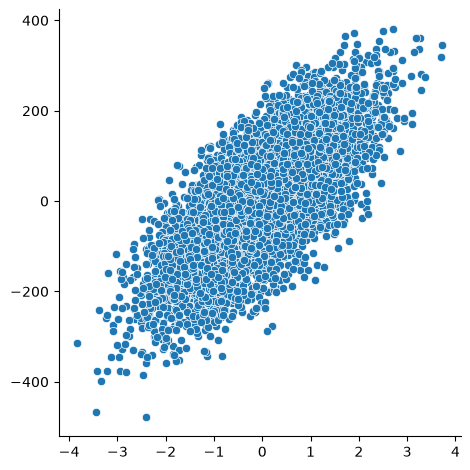

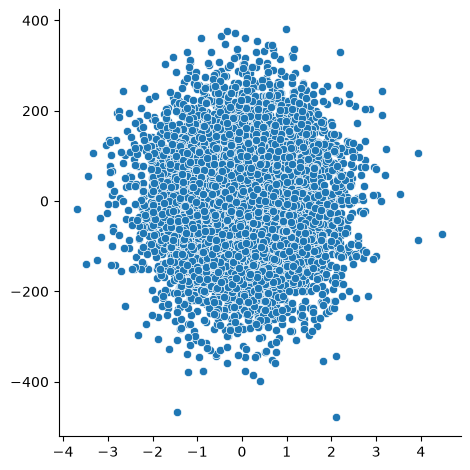

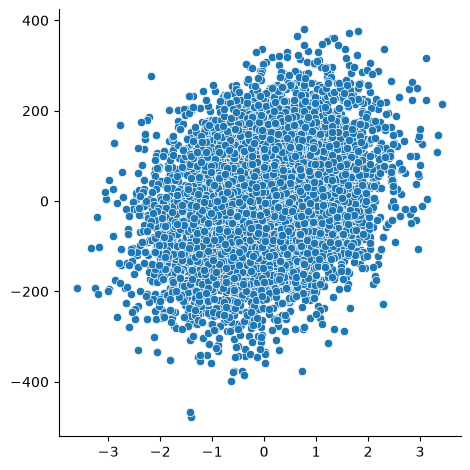

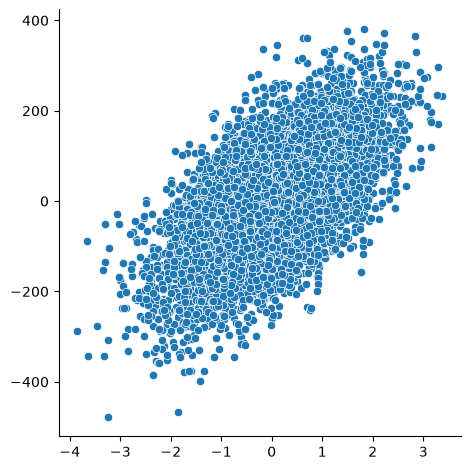

In [94]:
import seaborn as sns

for i in range(X_train.shape[1]):
    sns.relplot(kind='scatter',x=X_train[:,i],y=Y_train)


In [95]:
print(X_train[:,1])

[-0.02097996  0.09743629 -1.22589226 ...  1.05250237  0.32910678
 -1.47364718]


# **1. What is Dataset ?**

A PyTorch Dataset is a class that tells PyTorch:
- Where are my samples?
- How many samples do I have?
- How can I retrieve a particular sample and its label?
Think of it as a way to organize your data so PyTorch can access it consistently.

In [96]:
class MyDataset(Dataset):

    def __init__(self,x,y):

        self.device='cpu'
        self.x=torch.tensor(x,dtype=torch.float32,device=self.device)
        self.y=torch.tensor(y,dtype=torch.float32,device=self.device).reshape(-1,1)

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self,index):
        return self.x[index],self.y[index]

# **What is DataLoader ?**


Now imagine you have 700 samples.

You could train your model on all 700 samples at once, as you did previously.

But what if you have 100,000 or 1 million samples?

You might not want to pass the entire dataset to the model in one go.

This is where DataLoader comes in.

It automatically:
- Divides your dataset into batches.
- Retrieves samples from your Dataset.
- Shuffles the data if requested.
- Combines samples into batches.

In [97]:
train_dataset=MyDataset(X_train,Y_train)

train_loader=DataLoader(
    train_dataset,
    batch_size=100,
    shuffle=True
)


In [98]:
for batch_X, batch_y in train_loader:

    print(batch_X.shape)
    print(batch_y.shape)

    break

torch.Size([100, 4])
torch.Size([100, 1])


In [99]:

class CustomNN(nn.Module):

    def __init__(self, num_features):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(num_features, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, features):
        return self.network(features)


In [100]:
num_features = train_dataset[0][0].shape[0]

model = CustomNN(num_features)

In [101]:

# Loss function
loss_fn = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50

for epoch in range(epochs):

    model.train()

    total_loss = 0

    for X_batch, Y_batch in train_loader:

        # 1. Forward Pass
        y_pred = model(X_batch)

        # 2. Calculate Loss
        loss = loss_fn(y_pred, Y_batch)

        # 3. Clear Previous Gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update Weights
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    avg_loss = total_loss / len(train_dataset)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train MSE: {avg_loss:.4f}"
        )


Epoch [10/50] Train MSE: 57.1412
Epoch [20/50] Train MSE: 8.5677
Epoch [30/50] Train MSE: 2.6588
Epoch [40/50] Train MSE: 1.4992
Epoch [50/50] Train MSE: 0.9799


In [102]:
#When DataSet is Small
model.eval()

x_test=torch.tensor(x_test,dtype=torch.float32)
y_test=torch.tensor(y_test,dtype=torch.float32).reshape(-1,1)
with torch.no_grad():
    y_pred = model(x_test)
    test_loss = loss_fn(y_pred, y_test)

print("Test MSE:", test_loss.item())

Test MSE: 1.1016912460327148


In [103]:
#When DataSet is Large
model.eval()


test_dataset=MyDataset(x_test,y_test)

test_loader=DataLoader(
    test_dataset,
    batch_size=100,
    shuffle=False
)

total_loss=0.0

with torch.no_grad():

    for x_batch,y_batch in test_loader:

        y_pred=model(x_batch)
        loss=loss_fn(y_batch,y_pred)

        total_loss += loss.item() * x_batch.size(0)

avg_loss = total_loss / len(test_dataset)

print(f"Test MSE: {avg_loss:.4f}")

Test MSE: 1.1017


C:\Users\Tanishq\AppData\Local\Temp\ipykernel_23760\3859615523.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x=torch.tensor(x,dtype=torch.float32,device=self.device)
C:\Users\Tanishq\AppData\Local\Temp\ipykernel_23760\3859615523.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y=torch.tensor(y,dtype=torch.float32,device=self.device).reshape(-1,1)
